# Melt fraction and effective elastic properties: a tutorial based on `meltbenchmark.ipynb`

This notebook reorganizes the calculations in `meltbenchmark.ipynb`. Starting with the properties of the two phases, you will calculate the mixture's bulk modulus $K$, shear modulus $G$, and seismic velocities, then compare several effective medium models.

**How to run it:** Open this file from `ElasticC/notebooks/` and run the cells from top to bottom. You need `numpy`, `scipy`, `matplotlib`, and Jupyter. The notebook imports `elasticc` from this project, so it does not need a separate installation. If a dependency is missing, run `python -m pip install numpy scipy matplotlib jupyter` in a terminal.

**Units:** $K$ and $G$ are in GPa, density is in g/cm³, and velocities computed from $V=\sqrt{M/\rho}$ are in km/s. The original notebook uses the same density numbers but labels them as kg/m³ in its comments. Here, melt is phase 2 and its volume fraction is $f$.

## 1. Import the libraries

`context.py` adds the parent `ElasticC` directory to Python's search path, allowing this notebook to import the local `elasticc` package. `el.limits` provides elastic bounds, while `el.eep` provides the self-consistent and DEM models.

In [65]:
from context import elasticc as el
import numpy as np
import matplotlib.pyplot as plt

def seismic_velocities(K, G, density):
    # Convert moduli in GPa and density in g/cm³ to velocities in km/s.
    vp = np.sqrt((K + 4.0 * G / 3.0) / density)
    vs = np.sqrt(G / density)
    return vp, vs

## 2. Define the solid and melt properties

The original example treats the solid as isotropic: $C_{12}=C_{11}-2C_{44}$, $K_1=(C_{11}+2C_{12})/3$, and $G_1=C_{44}$. These equations give the same $K_1$ and $G_1$ without constructing the full $6\times6$ stiffness matrix. An ideal liquid has zero shear modulus; the code uses a very small positive value to avoid division by zero in some calculations.

Subscript `1` denotes the solid and `2` denotes the melt. Start by changing only the material parameters in the next cell, then observe how the results change.

In [66]:
# Solid phase: values from the original notebook
C11 = 136.03       # GPa
C44 = 39.86        # GPa
C12 = C11 - 2.0 * C44
K1 = (C11 + 2.0 * C12) / 3.0
G1 = C44
rho1 = 2.7292     # g/cm³

# Melt phase: values from the original notebook
K2 = 14.91         # GPa
G2 = 1e-12         # GPa; numerically close to zero
rho2 = 2.7         # g/cm³

vp1, vs1 = seismic_velocities(K1, G1, rho1)
vp2, vs2 = seismic_velocities(K2, G2, rho2)
print(f"Solid: K={K1:.3f} GPa, G={G1:.3f} GPa, Vp={vp1:.3f} km/s, Vs={vs1:.3f} km/s")
print(f"Melt: K={K2:.3f} GPa, G≈0 GPa, Vp={vp2:.3f} km/s, Vs≈0 km/s")

Solid: K=82.883 GPa, G=39.860 GPa, Vp=7.060 km/s, Vs=3.822 km/s
Melt: K=14.910 GPa, G≈0 GPa, Vp=2.350 km/s, Vs≈0 km/s


## 3. Create the melt-fraction grid and mixture density

`f` runs from 0.01 to 0.99 in steps of 0.01, so the solid fraction is `1-f`. We avoid the exact pure-phase endpoints because some later formulas can have zero denominators there. Density is the volume-weighted average: $\rho_{\mathrm{eff}}=(1-f)\rho_1+f\rho_2$.

In [67]:
f = np.arange(1, 100) / 100.0
solid_fraction = 1.0 - f
rho_eff = el.limits.Voigt(rho1, solid_fraction, rho2, f)

assert np.allclose(solid_fraction + f, 1.0)
print(f"{len(f)} melt-fraction values; range {f[0]:.2f}–{f[-1]:.2f}")

99 melt-fraction values; range 0.01–0.99


## 4. Calculate elastic-modulus bounds

- **Voigt:** A volume-weighted arithmetic average, usually an upper bound.
- **Reuss:** A harmonic average of the moduli, usually a lower bound.
- **Hashin–Shtrikman (HS):** Uses both phases' $K$ and $G$ to give tighter upper and lower bounds. The solid is stiffer in this example, so placing it first in the function gives the upper bound; swapping the phases gives the lower bound.

Argument order matters. `Voigt(a1, c1, a2, c2)` and `Reuss(a1, c1, a2, c2)` alternate property and fraction. `hs_bounds(K1, K2, G1, G2, c1, c2)` takes the two bulk moduli first, then the two shear moduli.

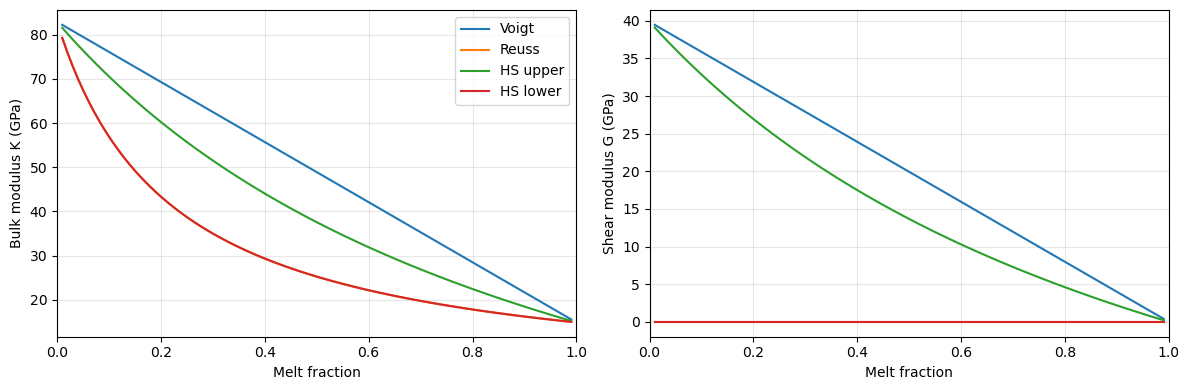

In [68]:
K_voigt = el.limits.Voigt(K1, solid_fraction, K2, f)
K_reuss = el.limits.Reuss(K1, solid_fraction, K2, f)
G_voigt = el.limits.Voigt(G1, solid_fraction, G2, f)
G_reuss = el.limits.Reuss(G1, solid_fraction, G2, f)

K_hs_upper, G_hs_upper = el.limits.hs_bounds(K1, K2, G1, G2, solid_fraction, f)
K_hs_lower, G_hs_lower = el.limits.hs_bounds(K2, K1, G2, G1, f, solid_fraction)

# Check the ordering of the bounds for this example.
assert np.all(K_reuss <= K_hs_lower + 1e-8)
assert np.all(K_hs_lower <= K_hs_upper + 1e-8)
assert np.all(K_hs_upper <= K_voigt + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, name, reuss, lower, upper, voigt in [
    (axes[0], "Bulk modulus K", K_reuss, K_hs_lower, K_hs_upper, K_voigt),
    (axes[1], "Shear modulus G", G_reuss, G_hs_lower, G_hs_upper, G_voigt),
]:
    ax.plot(f, voigt, label="Voigt")
    ax.plot(f, reuss, label="Reuss")
    ax.plot(f, upper, label="HS upper")
    ax.plot(f, lower, label="HS lower")
    ax.set(xlabel="Melt fraction", ylabel=f"{name} (GPa)", xlim=(0, 1))
    ax.grid(alpha=0.3)
axes[0].legend()
fig.tight_layout()
plt.show()

### 4.1 VRH: the midpoint of the Voigt and Reuss bounds

The **Voigt–Reuss–Hill (VRH) average** takes the arithmetic mean of the two bounds **separately for $K$ and $G$**:

$$K_{\rm VRH}=\frac{K_{\rm Voigt}+K_{\rm Reuss}}{2},\qquad
G_{\rm VRH}=\frac{G_{\rm Voigt}+G_{\rm Reuss}}{2}.$$

VRH is a convenient **estimate**, not another upper or lower bound. Here, melt has $G_2\approx0$, so the Reuss shear modulus is nearly zero whenever melt is present. Consequently, the VRH shear modulus is about half the Voigt value. This follows from the model assumptions; it is not a measured shear modulus.

### 4.2 HS: a tighter range than Voigt–Reuss

The Hashin–Shtrikman bounds give upper and lower values for both $K$ and $G$, using both phases' bulk and shear moduli. **The HS endpoints describe an allowed range, not two independent measurements.** The solid is stiffer in this example: placing it first in `hs_bounds` gives the upper bound, while swapping the phases gives the lower bound.

The next table compares values at $f=0.10$, using the same mixture density for every velocity calculation. **Average $K$ and $G$ first, then calculate the VRH velocities.** Do not average the Voigt and Reuss velocities directly, because the square-root conversion is nonlinear.

In [69]:
K_vrh = 0.5 * (K_voigt + K_reuss)
G_vrh = 0.5 * (G_voigt + G_reuss)
vp_vrh, vs_vrh = seismic_velocities(K_vrh, G_vrh, rho_eff)

example_index = np.argmin(np.abs(f - 0.10))
print(f"Melt fraction f={f[example_index]:.2f}; density={rho_eff[example_index]:.4f} g/cm³")
print(f"{'Estimate/bound':<12} {'K (GPa)':>10} {'G (GPa)':>10} {'Vp (km/s)':>12} {'Vs (km/s)':>12}")
for name, K_values, G_values in [
    ("Voigt", K_voigt, G_voigt),
    ("HS upper", K_hs_upper, G_hs_upper),
    ("VRH", K_vrh, G_vrh),
    ("HS lower", K_hs_lower, G_hs_lower),
    ("Reuss", K_reuss, G_reuss),
]:
    vp_values, vs_values = seismic_velocities(K_values, G_values, rho_eff)
    i = example_index
    print(f"{name:<12} {K_values[i]:10.3f} {G_values[i]:10.3f} "
          f"{vp_values[i]:12.3f} {vs_values[i]:12.3f}")


Melt fraction f=0.10; density=2.7263 g/cm³
Estimate/bound    K (GPa)    G (GPa)    Vp (km/s)    Vs (km/s)
Voigt            76.086     35.874        6.742        3.627
HS upper         70.531     32.863        6.476        3.472
VRH              66.508     17.937        5.759        2.565
HS lower         56.930      0.000        4.570        0.000
Reuss            56.930      0.000        4.570        0.000


**Correction to the original notebook:** Its calculations of `Gr` and `Gv` pass `K1, K2` into the functions. Here they use `G1, G2`, because these results are shear-modulus bounds. `G_reuss` is nearly zero because the liquid phase offers almost no resistance to shear.

## 5. Symmetric self-consistent approximation (SCA)

`mod_b` treats both phases and requires an aspect ratio, `a1` and `a2`, for each. Both are initially set to 1, meaning spherical shapes. The function returns effective $K$ and $G$, each an array with the same length as `f`.

The original example compares two calculation paths: **unrelaxed** directly treats melt as phase 2; **relaxed** first calculates a dry frame with empty pores, then uses `gassman_2` for fluid substitution. This notebook follows the original labels and definitions.

In [70]:
a1 = 1.0  # Solid aspect ratio: sphere
a2 = 1.0  # Melt aspect ratio: sphere

K_sca_unrelaxed, G_sca_unrelaxed = el.eep.mod_b(
    K1, K2, G1, G2, a1, a2, solid_fraction, f
)

K_sca_dry, G_sca_dry = el.eep.mod_b(
    K1, 0.0, G1, 0.0, a1, a2, solid_fraction, f
)
K_sca_relaxed, G_sca_relaxed = el.eep.gassman_2(
    K_sca_dry, G_sca_dry, K1, G1, K2, G2, f
)

## 6. Differential effective medium model (DEM)

`dem` starts with the solid and adds melt incrementally. It needs only the second phase's aspect ratio, `a2`, and requires the melt-fraction array to be sorted in ascending order. The dry-frame and fluid-substitution steps are the same as in the preceding section. The package's DEM uses approximate numerical integration, so the melt-fraction grid spacing can affect the result.

In [71]:
K_dem_unrelaxed, G_dem_unrelaxed = el.eep.dem(K1, K2, G1, G2, a2, f)

K_dem_dry, G_dem_dry = el.eep.dem(K1, 0.0, G1, 0.0, a2, f)
K_dem_relaxed, G_dem_relaxed = el.eep.gassman_2(
    K_dem_dry, G_dem_dry, K1, G1, K2, G2, f
)

## 7. Compare the effective moduli

The left panel shows bulk modulus and the right panel shows shear modulus. Gray lines are the HS bounds; solid lines are unrelaxed and dashed lines are relaxed. Compare the models and the effect of the two calculation paths.

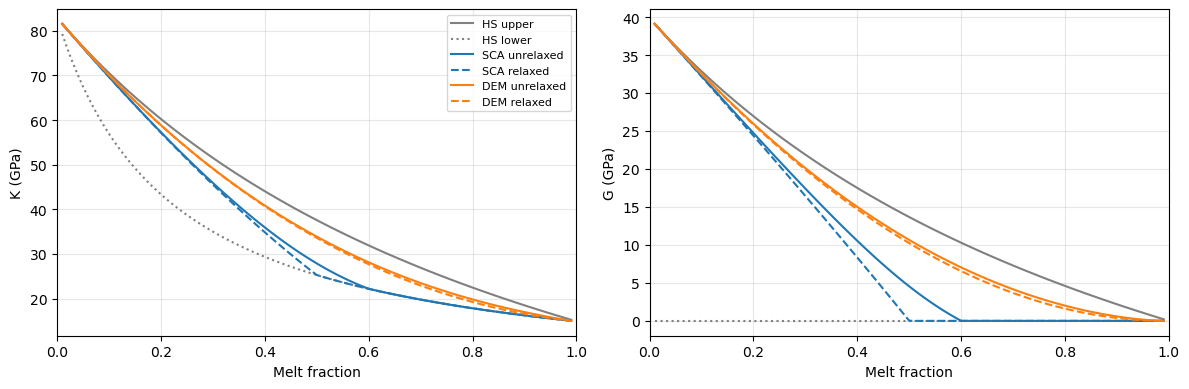

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, name, hs_low, hs_high, sca_u, sca_r, dem_u, dem_r in [
    (axes[0], "K", K_hs_lower, K_hs_upper,
     K_sca_unrelaxed, K_sca_relaxed, K_dem_unrelaxed, K_dem_relaxed),
    (axes[1], "G", G_hs_lower, G_hs_upper,
     G_sca_unrelaxed, G_sca_relaxed, G_dem_unrelaxed, G_dem_relaxed),
]:
    ax.plot(f, hs_high, color="0.5", label="HS upper")
    ax.plot(f, hs_low, color="0.5", linestyle=":", label="HS lower")
    ax.plot(f, sca_u, color="C0", label="SCA unrelaxed")
    ax.plot(f, sca_r, color="C0", linestyle="--", label="SCA relaxed")
    ax.plot(f, dem_u, color="C1", label="DEM unrelaxed")
    ax.plot(f, dem_r, color="C1", linestyle="--", label="DEM relaxed")
    ax.set(xlabel="Melt fraction", ylabel=f"{name} (GPa)", xlim=(0, 1))
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8. Convert K, G, and density to Vp and Vs

$K$ and $G$ alone are not enough: you also need the density $\rho$ of the same material. We calculated the mixture density `rho_eff` at every melt fraction, so we can convert each point:

$$V_p=\sqrt{\frac{K+4G/3}{\rho}},\qquad V_s=\sqrt{\frac{G}{\rho}}.$$

With $K,G$ in **GPa** and density in **g/cm³**, the resulting $V_p,V_s$ are in **km/s**. `seismic_velocities(K, G, density)` accepts either scalars or NumPy arrays. The next cell calculates velocities for Voigt, Reuss, VRH, HS, SCA, and DEM.

In [73]:
vp_voigt, vs_voigt = seismic_velocities(K_voigt, G_voigt, rho_eff)
vp_reuss, vs_reuss = seismic_velocities(K_reuss, G_reuss, rho_eff)
vp_vrh, vs_vrh = seismic_velocities(K_vrh, G_vrh, rho_eff)
vp_hs_upper, vs_hs_upper = seismic_velocities(K_hs_upper, G_hs_upper, rho_eff)
vp_hs_lower, vs_hs_lower = seismic_velocities(K_hs_lower, G_hs_lower, rho_eff)

vp_sca_unrelaxed, vs_sca_unrelaxed = seismic_velocities(
    K_sca_unrelaxed, G_sca_unrelaxed, rho_eff
)
vp_sca_relaxed, vs_sca_relaxed = seismic_velocities(
    K_sca_relaxed, G_sca_relaxed, rho_eff
)
vp_dem_unrelaxed, vs_dem_unrelaxed = seismic_velocities(
    K_dem_unrelaxed, G_dem_unrelaxed, rho_eff
)
vp_dem_relaxed, vs_dem_relaxed = seismic_velocities(
    K_dem_relaxed, G_dem_relaxed, rho_eff
)


## 9. Plot Vp and Vs against melt fraction

Gray lines show the HS bounds, blue lines show SCA, and orange lines show DEM. Solid model lines are unrelaxed; dashed lines are relaxed. The left panel shows $V_p$ and the right panel shows $V_s$.

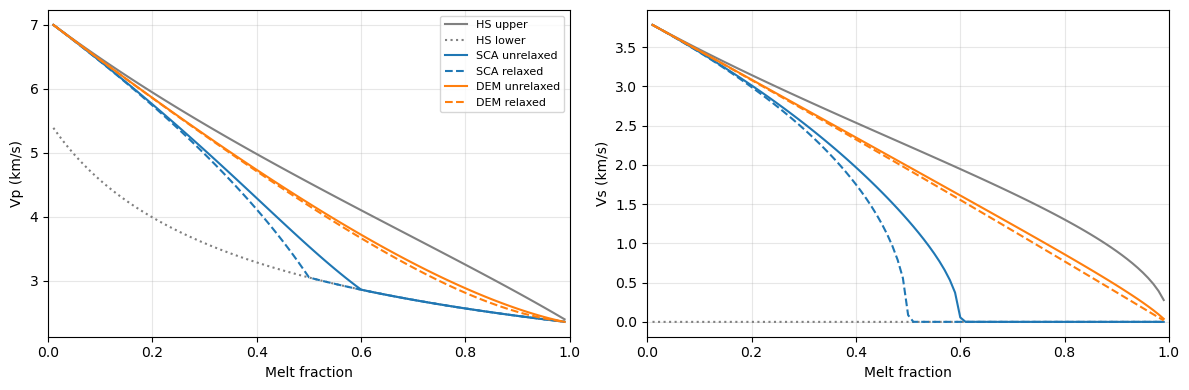

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, name, hs_low, hs_high, sca_u, sca_r, dem_u, dem_r in [
    (axes[0], "Vp", vp_hs_lower, vp_hs_upper,
     vp_sca_unrelaxed, vp_sca_relaxed, vp_dem_unrelaxed, vp_dem_relaxed),
    (axes[1], "Vs", vs_hs_lower, vs_hs_upper,
     vs_sca_unrelaxed, vs_sca_relaxed, vs_dem_unrelaxed, vs_dem_relaxed),
]:
    ax.plot(f, hs_high, color="0.5", label="HS upper")
    ax.plot(f, hs_low, color="0.5", linestyle=":", label="HS lower")
    ax.plot(f, sca_u, color="C0", label="SCA unrelaxed")
    ax.plot(f, sca_r, color="C0", linestyle="--", label="SCA relaxed")
    ax.plot(f, dem_u, color="C1", label="DEM unrelaxed")
    ax.plot(f, dem_r, color="C1", linestyle="--", label="DEM relaxed")
    ax.set(xlabel="Melt fraction", ylabel=f"{name} (km/s)", xlim=(0, 1))
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 10. Read values at a selected melt fraction

The next cell lists each model's $K$, $G$, $V_p$, and $V_s$ at the grid point closest to `target_fraction = 0.10`. Change `target_fraction` and rerun only that cell to inspect another fraction.

In [75]:
target_fraction = 0.10
index = np.argmin(np.abs(f - target_fraction))
print(f"Nearest grid point f={f[index]:.2f}; density={rho_eff[index]:.4f} g/cm³")
print(f"{'Model':<18} {'K (GPa)':>10} {'G (GPa)':>10} {'Vp (km/s)':>12} {'Vs (km/s)':>12}")
results = [
    ("Voigt", K_voigt, G_voigt, vp_voigt, vs_voigt),
    ("Reuss", K_reuss, G_reuss, vp_reuss, vs_reuss),
    ("VRH", K_vrh, G_vrh, vp_vrh, vs_vrh),
    ("HS upper", K_hs_upper, G_hs_upper, vp_hs_upper, vs_hs_upper),
    ("HS lower", K_hs_lower, G_hs_lower, vp_hs_lower, vs_hs_lower),
    ("SCA unrelaxed", K_sca_unrelaxed, G_sca_unrelaxed, vp_sca_unrelaxed, vs_sca_unrelaxed),
    ("SCA relaxed", K_sca_relaxed, G_sca_relaxed, vp_sca_relaxed, vs_sca_relaxed),
    ("DEM unrelaxed", K_dem_unrelaxed, G_dem_unrelaxed, vp_dem_unrelaxed, vs_dem_unrelaxed),
    ("DEM relaxed", K_dem_relaxed, G_dem_relaxed, vp_dem_relaxed, vs_dem_relaxed),
]
for name, K, G, vp, vs in results:
    print(f"{name:<18} {K[index]:10.3f} {G[index]:10.3f} {vp[index]:12.3f} {vs[index]:12.3f}")


Nearest grid point f=0.10; density=2.7263 g/cm³
Model                 K (GPa)    G (GPa)    Vp (km/s)    Vs (km/s)
Voigt                  76.086     35.874        6.742        3.627
Reuss                  56.930      0.000        4.570        0.000
VRH                    66.508     17.937        5.759        2.565
HS upper               70.531     32.863        6.476        3.472
HS lower               56.930      0.000        4.570        0.000
SCA unrelaxed          69.659     32.248        6.428        3.439
SCA relaxed            69.650     32.174        6.425        3.435
DEM unrelaxed          70.055     32.541        6.451        3.455
DEM relaxed            70.075     32.512        6.450        3.453


## 11. Use your own K, G, and density

If you have one set of material properties, call the same function directly. The example uses $K=50$ GPa, $G=30$ GPa, and $\rho=2.7$ g/cm³. Replace them with your values and rerun the next cell. If your density is in kg/m³, divide it by 1000 to convert it to g/cm³.

In [76]:
my_K = 50.0       # GPa
my_G = 30.0       # GPa
my_density = 2.7  # g/cm³
my_vp, my_vs = seismic_velocities(my_K, my_G, my_density)
print(f"Vp = {my_vp:.3f} km/s, Vs = {my_vs:.3f} km/s")


Vp = 5.774 km/s, Vs = 3.333 km/s


# Connecting the models to the paper: from velocity to melt fraction

**Reading:** [Paulatto et al. (2022), *Advances in seismic imaging of magma and crystal mush*](https://www.frontiersin.org/journals/earth-science/articles/10.3389/feart.2022.970131/full), especially Sections 3.1–3.3 and Figure 5. This review connects seismic imaging, effective medium models, and melt-fraction estimates.

> **The paper's point:** Seismic imaging primarily constrains effective elastic properties such as velocity. Inferring melt fraction also requires assumptions about composition, density, melt shape, and connectivity. Figure 5 shows that different models and shapes can predict different velocities at the same melt fraction.
>
> **This tutorial's example:** The calculations below keep the two-phase properties from `meltbenchmark.ipynb`. Those properties differ from the materials used in the paper's Figure 5. These curves are **not** an exact reproduction of that figure or an estimate for a particular volcano.

## 12. Compare DEM melt-inclusion aspect ratios from 0.05 to 2

Hold the phases' $K$, $G$, density, and melt-fraction grid fixed, and change only melt aspect ratio `a2`. Values below 1 describe oblate spheroids; `a2=1` is a sphere; values above 1 describe prolate spheroids. For seven aspect ratios—`0.05, 0.1, 0.2, 0.5, 1, 1.5, 2`—DEM calculates effective $K$ and $G$, which we convert to $V_p$ and $V_s$. The third panel shows the dimensionless ratio $V_p/V_s$. The table compares all shapes at 10% melt. Calculate each ratio using $V_p$ and $V_s$ from the **same model and melt fraction**.

Figure 5B/E of the paper also compares aspect ratios, but uses SCS. This section extends the exercise to **DEM** with this notebook's material properties; its numerical curves therefore differ from the paper's. DEM adds dispersed melt inclusions incrementally. Interpret its predictions cautiously if the melt forms a connected network at higher fractions. The ratio panel uses the current plotting limits, so values outside its y-axis range are clipped.

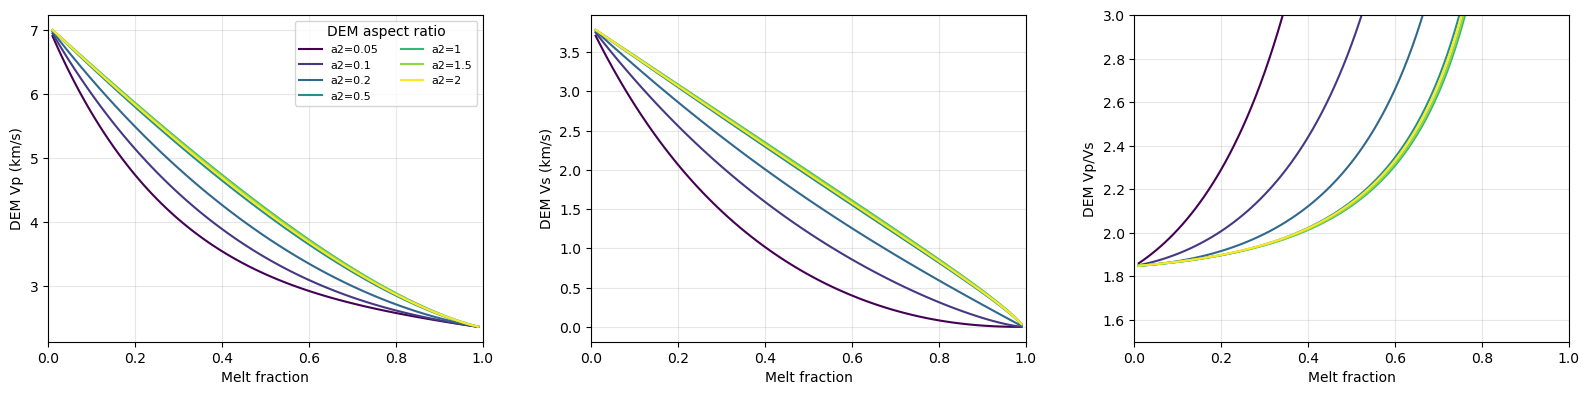

Melt fraction f=0.10; density=2.7263 g/cm³
   a2    K (GPa)    G (GPa)    Vp (km/s)    Vs (km/s)    Vp/Vs
 0.05     59.486     21.805        5.699        2.828    2.015
 0.10     61.967     27.035        5.996        3.149    1.904
 0.20     65.354     30.214        6.225        3.329    1.870
 0.50     69.215     32.192        6.413        3.436    1.866
 1.00     70.055     32.541        6.451        3.455    1.867
 1.50     69.891     32.462        6.443        3.451    1.867
 2.00     69.669     32.342        6.432        3.444    1.867


In [77]:
aspect_ratios = (0.05, 0.1, 0.2, 0.5, 1.0, 1.5, 2.0)
shape_curves = {}  # DEM; key: a2; value: (Vp array, Vs array)
shape_moduli = {}  # Key: a2; value: (K array, G array)
dem_ratio_curves = {}  # Key: a2; value: dimensionless Vp/Vs array

for aspect_ratio in aspect_ratios:
    K_shape, G_shape = el.eep.dem(K1, K2, G1, G2, aspect_ratio, f)
    vp_shape, vs_shape = seismic_velocities(K_shape, G_shape, rho_eff)
    ratio_shape = np.divide(
        vp_shape, vs_shape, out=np.full_like(vp_shape, np.nan), where=vs_shape > 0
    )
    shape_moduli[aspect_ratio] = (K_shape, G_shape)
    shape_curves[aspect_ratio] = (vp_shape, vs_shape)
    dem_ratio_curves[aspect_ratio] = ratio_shape

plot_mask = f <= 0.99
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(aspect_ratios)))
for aspect_ratio, color in zip(aspect_ratios, colors):
    vp_shape, vs_shape = shape_curves[aspect_ratio]
    ratio_shape = dem_ratio_curves[aspect_ratio]
    axes[0].plot(f[plot_mask], vp_shape[plot_mask], color=color, label=f"a2={aspect_ratio:g}")
    axes[1].plot(f[plot_mask], vs_shape[plot_mask], color=color)
    axes[2].plot(f[plot_mask], ratio_shape[plot_mask], color=color)
for ax, ylabel in zip(axes, ("DEM Vp (km/s)", "DEM Vs (km/s)", "DEM Vp/Vs")):
    ax.set(xlabel="Melt fraction", ylabel=ylabel, xlim=(0, 1))
    ax.grid(alpha=0.3)
axes[0].legend(title="DEM aspect ratio", fontsize=8, ncol=2)
fig.tight_layout()
axes[2].set(ylim=(1.5, 3))
plt.show()



index_10 = np.argmin(np.abs(f - 0.10))
print(f"Melt fraction f={f[index_10]:.2f}; density={rho_eff[index_10]:.4f} g/cm³")
print(f"{'a2':>5} {'K (GPa)':>10} {'G (GPa)':>10} {'Vp (km/s)':>12} "
      f"{'Vs (km/s)':>12} {'Vp/Vs':>8}")
for aspect_ratio in aspect_ratios:
    K_shape, G_shape = shape_moduli[aspect_ratio]
    vp_shape, vs_shape = shape_curves[aspect_ratio]
    ratio_shape = dem_ratio_curves[aspect_ratio]
    i = index_10
    print(f"{aspect_ratio:5.2f} {K_shape[i]:10.3f} {G_shape[i]:10.3f} "
          f"{vp_shape[i]:12.3f} {vs_shape[i]:12.3f} {ratio_shape[i]:8.3f}")


### 12.1 Compare the same aspect ratios with SCS

SCS means **self-consistent scheme**. This package implements it as `mod_b`; earlier sections also call it SCA. SCS uses the **same material properties, density, melt-fraction grid, and seven `a2` values** as DEM in Section 12. We hold the solid's aspect ratio at `a1=1` and vary only the melt's aspect ratio. `mod_b` finds effective $K$ and $G$ by iterating a mixture in which both phases are embedded in the effective medium. DEM instead starts with the solid and adds melt incrementally.

The three panels show SCS $V_p$, $V_s$, and dimensionless $V_p/V_s$ for comparison with the DEM panels. At some high melt fractions, SCS predicts $V_s$ close to zero, making $V_p/V_s$ very large. The ratio panel therefore uses a **logarithmic y-axis** and shows only $f\leq0.5$. If $V_s=0$, the ratio is undefined. The table compares the models at 10% melt; `SCS − DEM` is a difference between model predictions, not an observational error.

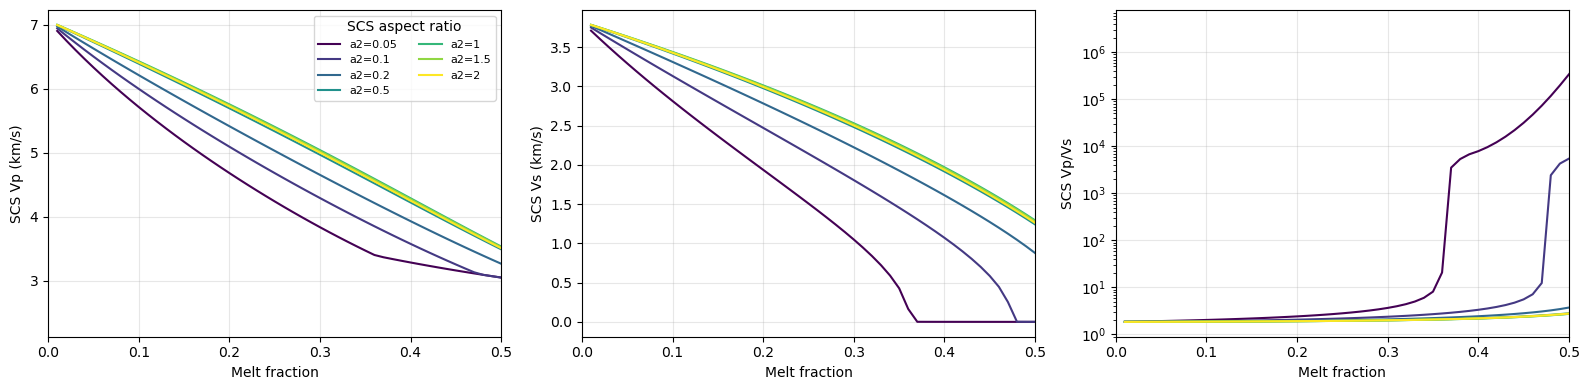

Melt fraction f=0.10; density=2.7263 g/cm³
   a2    K (GPa)    G (GPa)    Vp (km/s)    Vs (km/s)    Vp/Vs    Δratio
 0.05     60.258     21.588        5.715        2.814    2.031     0.016
 0.10     62.406     26.765        5.998        3.133    1.914     0.010
 0.20     65.337     29.915        6.213        3.313    1.875     0.006
 0.50     68.860     31.895        6.392        3.420    1.869     0.002
 1.00     69.659     32.248        6.428        3.439    1.869     0.002
 1.50     69.501     32.168        6.421        3.435    1.869     0.002
 2.00     69.287     32.046        6.410        3.428    1.870     0.002


In [78]:
scs_shape_curves = {}  # Key: a2; value: (Vp array, Vs array)
scs_shape_moduli = {}  # Key: a2; value: (K array, G array)
scs_ratio_curves = {}  # Key: a2; value: dimensionless Vp/Vs array

for aspect_ratio in aspect_ratios:
    K_scs, G_scs = el.eep.mod_b(
        K1, K2, G1, G2, a1, aspect_ratio, solid_fraction, f
    )
    vp_scs, vs_scs = seismic_velocities(K_scs, G_scs, rho_eff)
    ratio_scs = np.divide(
        vp_scs, vs_scs, out=np.full_like(vp_scs, np.nan), where=vs_scs > 0
    )
    scs_shape_moduli[aspect_ratio] = (K_scs, G_scs)
    scs_shape_curves[aspect_ratio] = (vp_scs, vs_scs)
    scs_ratio_curves[aspect_ratio] = ratio_scs

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for aspect_ratio, color in zip(aspect_ratios, colors):
    vp_scs, vs_scs = scs_shape_curves[aspect_ratio]
    ratio_scs = scs_ratio_curves[aspect_ratio]
    axes[0].plot(f[plot_mask], vp_scs[plot_mask], color=color, label=f"a2={aspect_ratio:g}")
    axes[1].plot(f[plot_mask], vs_scs[plot_mask], color=color)
    axes[2].plot(f[plot_mask], ratio_scs[plot_mask], color=color)
for ax, ylabel in zip(axes, ("SCS Vp (km/s)", "SCS Vs (km/s)", "SCS Vp/Vs")):
    ax.set(xlabel="Melt fraction", ylabel=ylabel, xlim=(0, 0.5))
    ax.grid(alpha=0.3)
axes[2].set_yscale("log")  # The ratio can become very large as Vs approaches zero.
axes[0].legend(title="SCS aspect ratio", fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

print(f"Melt fraction f={f[index_10]:.2f}; density={rho_eff[index_10]:.4f} g/cm³")
print(f"{'a2':>5} {'K (GPa)':>10} {'G (GPa)':>10} {'Vp (km/s)':>12} "
      f"{'Vs (km/s)':>12} {'Vp/Vs':>8} {'Δratio':>9}")
for aspect_ratio in aspect_ratios:
    K_scs, G_scs = scs_shape_moduli[aspect_ratio]
    vp_scs, vs_scs = scs_shape_curves[aspect_ratio]
    ratio_scs = scs_ratio_curves[aspect_ratio]
    ratio_dem = dem_ratio_curves[aspect_ratio]
    i = index_10
    print(f"{aspect_ratio:5.2f} {K_scs[i]:10.3f} {G_scs[i]:10.3f} "
          f"{vp_scs[i]:12.3f} {vs_scs[i]:12.3f} "
          f"{ratio_scs[i]:8.3f} {ratio_scs[i] - ratio_dem[i]:9.3f}")


### 12.2 Compare critical porosity with DEM and SCS

The **critical-porosity model** specifies a melt fraction $\phi_c$ at which the solid framework loses its load-bearing ability. In this project, `el.critical.mod_c(K1, K2, G1, G2, phic, f)` makes the **dry-frame** $K$ and $G$ decrease linearly with $f/\phi_c$ below that threshold, then applies Gassmann fluid substitution. At $f\geq\phi_c$, the dry-frame $G$ is zero. Thus $V_s=0$ and $V_p/V_s$ is **undefined**, although fluid-saturated $K$ and $V_p$ can remain finite.

For a useful comparison, keep the **phase properties, density, and melt-fraction grid identical**. Choose one DEM/SCS melt aspect ratio (here `a2=0.2`). Since `mod_c` uses a dry frame and fluid substitution, the DEM/SCS comparison curves below use the same **dry frame + `gassman_2`** route. They differ slightly from the curves in Sections 12 and 12.1, which put melt directly into the second phase. Critical porosity uses `phic`, **not** an aspect ratio. `0.30` and `0.35` are illustrative values; they have not been measured for the solid used here.

Compare three features: (1) $V_p$ at the same $f$; (2) the $f$ at which $V_s$ approaches zero; and (3) how $V_p/V_s$ increases as $V_s$ approaches zero. The third panel uses a logarithmic y-axis. The critical-porosity curves stop at $f\geq\phi_c$ because the ratio is undefined there. Figure 5C/F of the paper compares a critical-porosity model with the SCS/DEM models in Figure 5A/D. The material properties here come from the original notebook, so this is not a numerical reproduction of the paper's figure.

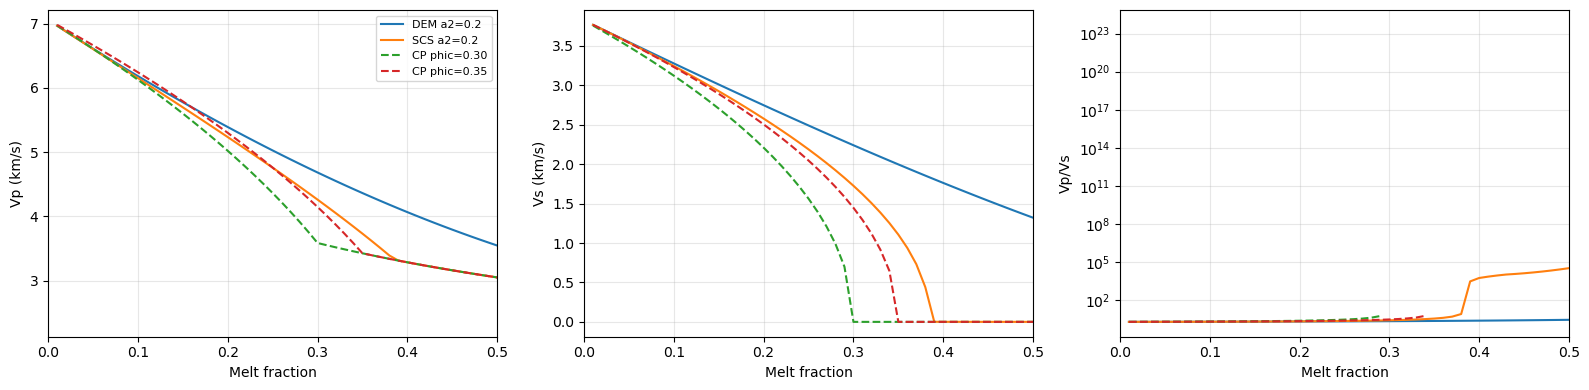


f=0.10; density=2.7263 g/cm³
Model                K (GPa)    G (GPa)    Vp (km/s)    Vs (km/s)    Vp/Vs
DEM a2=0.2            65.240     29.286        6.185        3.278    1.887
SCS a2=0.2            64.988     28.692        6.154        3.244    1.897
CP phic=0.30          66.924     26.573        6.127        3.122    1.963
CP phic=0.35          68.326     28.471        6.244        3.232    1.932

f=0.30; density=2.7204 g/cm³
Model                K (GPa)    G (GPa)    Vp (km/s)    Vs (km/s)    Vp/Vs
DEM a2=0.2            41.502     13.651        4.685        2.240    2.091
SCS a2=0.2            38.615      8.106        4.262        1.726    2.469
CP phic=0.30          35.006      0.000        3.587        0.000 undefined
CP phic=0.35          39.211      5.694        4.148        1.447    2.867


In [79]:
reference_aspect_ratio = 0.2
critical_values = (0.30, 0.35)
comparison_curves = {}  # Key: model name; value: (K, G, Vp, Vs, Vp/Vs)

# Match the dry-frame plus fluid-substitution route used by critical.mod_c.
K_dem_dry_cmp, G_dem_dry_cmp = el.eep.dem(
    K1, 0.0, G1, 0.0, reference_aspect_ratio, f
)
K_dem_cmp, G_dem_cmp = el.eep.gassman_2(
    K_dem_dry_cmp, G_dem_dry_cmp, K1, G1, K2, G2, f
)
K_scs_dry_cmp, G_scs_dry_cmp = el.eep.mod_b(
    K1, 0.0, G1, 0.0, a1, reference_aspect_ratio, solid_fraction, f
)
K_scs_cmp, G_scs_cmp = el.eep.gassman_2(
    K_scs_dry_cmp, G_scs_dry_cmp, K1, G1, K2, G2, f
)

for name, K_values, G_values in [
    ("DEM a2=0.2", K_dem_cmp, G_dem_cmp),
    ("SCS a2=0.2", K_scs_cmp, G_scs_cmp),
]:
    vp_values, vs_values = seismic_velocities(K_values, G_values, rho_eff)
    ratio_values = np.divide(
        vp_values, vs_values, out=np.full_like(vp_values, np.nan), where=vs_values > 0
    )
    comparison_curves[name] = (K_values, G_values, vp_values, vs_values, ratio_values)

for phic in critical_values:
    K_cp, G_cp = el.critical.mod_c(K1, K2, G1, G2, phic, f)
    vp_cp, vs_cp = seismic_velocities(K_cp, G_cp, rho_eff)
    ratio_cp = np.divide(
        vp_cp, vs_cp, out=np.full_like(vp_cp, np.nan), where=vs_cp > 0
    )
    comparison_curves[f"CP phic={phic:.2f}"] = (K_cp, G_cp, vp_cp, vs_cp, ratio_cp)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
styles = {
    "DEM a2=0.2": ("C0", "-"),
    "SCS a2=0.2": ("C1", "-"),
    "CP phic=0.30": ("C2", "--"),
    "CP phic=0.35": ("C3", "--"),
}
for name, (K_values, G_values, vp_values, vs_values, ratio_values) in comparison_curves.items():
    color, linestyle = styles[name]
    for ax, values in zip(axes, (vp_values, vs_values, ratio_values)):
        ax.plot(f[plot_mask], values[plot_mask], color=color,
                linestyle=linestyle, label=name)
for ax, ylabel in zip(axes, ("Vp (km/s)", "Vs (km/s)", "Vp/Vs")):
    ax.set(xlabel="Melt fraction", ylabel=ylabel, xlim=(0, 0.5))
    ax.grid(alpha=0.3)
axes[2].set_yscale("log")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

for fraction_to_show in (0.10, 0.30):
    i = np.argmin(np.abs(f - fraction_to_show))
    print(f"\nf={f[i]:.2f}; density={rho_eff[i]:.4f} g/cm³")
    print(f"{'Model':<17} {'K (GPa)':>10} {'G (GPa)':>10} "
          f"{'Vp (km/s)':>12} {'Vs (km/s)':>12} {'Vp/Vs':>8}")
    for name, (K_values, G_values, vp_values, vs_values, ratio_values) in comparison_curves.items():
        ratio_text = f"{ratio_values[i]:.3f}" if np.isfinite(ratio_values[i]) else "undefined"
        print(f"{name:<17} {K_values[i]:10.3f} {G_values[i]:10.3f} "
              f"{vp_values[i]:12.3f} {vs_values[i]:12.3f} {ratio_text:>8}")


## 13. Infer melt fraction from an observed Vp: a synthetic exercise

Suppose the “observed” $V_p$ equals the DEM prediction at `a2=0.2` and 10% melt. For each DEM shape curve in Section 12, interpolate to find the melt fraction matching that $V_p$. We generated this observation ourselves, so recovering 10% for `a2=0.2` only checks the method. The different answers for other shapes are the point of the exercise.

Assume an observational uncertainty of ±0.10 km/s in $V_p$. The next cell reports the permitted melt-fraction interval for each shape. These intervals show only the effects of velocity uncertainty and shape choice; they do not include uncertainties in material properties, temperature, pressure, or imaging resolution.

In [80]:
observed_vp = shape_curves[0.2][0][index_10]  # Synthetic observation in km/s
observed_vs = shape_curves[0.2][1][index_10]
vp_error = 0.10  # Assumed observation uncertainty in km/s

print(f"Synthetic observation: Vp={observed_vp:.3f} ± {vp_error:.2f} km/s; "
      f"Vs={observed_vs:.3f} km/s")
print(f"{'a2':>5} {'f from Vp':>10} {'f range from Vp error':>22} {'Predicted Vs (km/s)':>17}")
for aspect_ratio, (vp_curve, vs_curve) in shape_curves.items():
    # np.interp needs increasing x values; reverse arrays because Vp decreases with f.
    assert np.all(np.diff(vp_curve) < 0)
    fraction_est = np.interp(observed_vp, vp_curve[::-1], f[::-1])
    fraction_low = np.interp(observed_vp + vp_error, vp_curve[::-1], f[::-1])
    fraction_high = np.interp(observed_vp - vp_error, vp_curve[::-1], f[::-1])
    vs_pred = np.interp(fraction_est, f, vs_curve)
    print(f"{aspect_ratio:5.2f} {fraction_est:10.3f} "
          f"{fraction_low:9.3f}–{fraction_high:.3f} {vs_pred:17.3f}")


Synthetic observation: Vp=6.225 ± 0.10 km/s; Vs=3.329 km/s
   a2  f from Vp  f range from Vp error Predicted Vs (km/s)
 0.05      0.057     0.050–0.065             3.221
 0.10      0.077     0.067–0.087             3.299
 0.20      0.100     0.087–0.113             3.329
 0.50      0.130     0.114–0.146             3.321
 1.00      0.138     0.121–0.155             3.316
 1.50      0.136     0.119–0.153             3.317
 2.00      0.134     0.117–0.150             3.317


## 14. Interpret the results

- **Forward problem:** Given melt fraction, both phases' $K/G/\rho$, inclusion shape, and a model, calculate $V_p$ and $V_s$. The preceding calculations solve this problem.
- **Inverse problem:** Given an observed velocity, estimate melt fraction. Section 13 shows that different shape assumptions give different fractions even at the same $V_p$. A reliable $V_s$ measurement can test or narrow the candidate models.
- **Imaging limits:** Sections 2.8–2.9 of the paper discuss resolution and wavefront healing. Imaging can smooth a small low-velocity body, making the observed anomaly weaker than the true one. The curve inversion above is a rock-physics exercise; it does not simulate seismic acquisition, wave propagation, or imaging.

**Try next:** Change `observed_vp` to 6.0 km/s or `vp_error` to 0.05 km/s and inspect the melt-fraction intervals. For real data, assess the reference solid velocity, composition, temperature, pressure, density, and imaging resolution. Report results across plausible shapes and models rather than a single melt fraction.

In [81]:
observed_vp = 6.0 #shape_curves[0.2][0][index_10]  # Synthetic observation in km/s
vp_error = 0.05 #0.10  # Assumed observation uncertainty in km/s

print(f"Assumed observation: Vp={observed_vp:.3f} ± {vp_error:.2f} km/s; no observed Vs is specified here")
print(f"{'a2':>5} {'f from Vp':>10} {'f range from Vp error':>22} {'Predicted Vs (km/s)':>17}")
for aspect_ratio, (vp_curve, vs_curve) in shape_curves.items():
    # np.interp needs increasing x values; reverse arrays because Vp decreases with f.
    assert np.all(np.diff(vp_curve) < 0)
    fraction_est = np.interp(observed_vp, vp_curve[::-1], f[::-1])
    fraction_low = np.interp(observed_vp + vp_error, vp_curve[::-1], f[::-1])
    fraction_high = np.interp(observed_vp - vp_error, vp_curve[::-1], f[::-1])
    vs_pred = np.interp(fraction_est, f, vs_curve)
    print(f"{aspect_ratio:5.2f} {fraction_est:10.3f} "
          f"{fraction_low:9.3f}–{fraction_high:.3f} {vs_pred:17.3f}")


Assumed observation: Vp=6.000 ± 0.05 km/s; no observed Vs is specified here
   a2  f from Vp  f range from Vp error Predicted Vs (km/s)
 0.05      0.075     0.071–0.079             3.055
 0.10      0.100     0.094–0.105             3.152
 0.20      0.129     0.123–0.136             3.190
 0.50      0.166     0.158–0.174             3.182
 1.00      0.176     0.167–0.184             3.176
 1.50      0.174     0.165–0.182             3.177
 2.00      0.171     0.163–0.179             3.177
